In [1]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from scipy.interpolate import Akima1DInterpolator
import numpy as np
import pywt
import sys
sys.path.append('..')
from spectraderma_processor import SpectraDermaProcessor

mpl.rcParams['font.family'] = 'arial'
mpl.rcParams['font.size'] = 10

colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

In [2]:
# Initialize processor
processor = SpectraDermaProcessor()

# 555S2

In [59]:
processor.load_data('../data/spectraderama_data_2025-04-02_sattac555S2.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (456719, 6)
First few rows:
     0    1    2    3    4    5
0  1.0  2.0  5.0  6.0  6.0  4.0
1  1.0  2.0  5.0  6.0  6.0  4.0
2  1.0  2.0  5.0  6.0  6.0  4.0
3  1.0  2.0  5.0  6.0  6.0  4.0
4  1.0  2.0  5.0  6.0  6.0  4.0


c:\Users\y1hli\OneDrive - University of North Carolina at Chapel Hill\github\SpectraDerma\notebooks\..\spectraderma_processor.py:17: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(csv_path)


In [60]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=2.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (456719, 6)


In [61]:
t1 = 2450
t2 = 389100
d = 300

time_limits_1 = (t1, t1 + d)
time_limits_2 = (t2, t2 + d)

amplitude_limits = (-25, 25)

# Use processor's normalize method with both time regions
processor.normalize(time_limits_1, time_limits_2, amplitude_limits=amplitude_limits)

# Get normalized data
timestamp, channels_swt_f_normalized = processor.get_data()
print(f"Normalized data shape: {channels_swt_f_normalized.shape}")

Normalized data shape: (456719, 6)


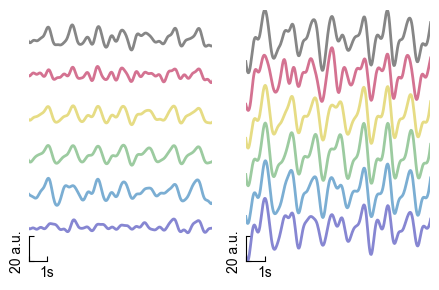

In [62]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(4.5, 3))

sample_rate = 30.0
y_offset = 30  # Small offset between channels

# Left subplot - first time region
ax_left = axes[0]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_left.plot(timestamp, y, color=colors[i], alpha=1, linewidth=2)

ax_left.set_xlim(*time_limits_1)
ax_left.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (30 samples)
ax_left.spines['bottom'].set_bounds(time_limits_1[0], time_limits_1[0] + 30)
# Left spine: show only 20 units
ax_left.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_left.spines['top'].set_visible(False)
ax_left.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_left.set_xticks([time_limits_1[0], time_limits_1[0] + 30])
ax_left.set_xticklabels(['', '1s'])
ax_left.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_left.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_left.tick_params(axis='both', which='both', direction='in')

# Right subplot - second time region
ax_right = axes[1]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_right.plot(timestamp, y, color=colors[i], alpha=1, linewidth=2)

ax_right.set_xlim(*time_limits_2)
ax_right.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (30 samples)
ax_right.spines['bottom'].set_bounds(time_limits_2[0], time_limits_2[0] + 30)
# Left spine: show only 20 units
ax_right.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_right.spines['top'].set_visible(False)
ax_right.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_right.set_xticks([time_limits_2[0], time_limits_2[0] + 30])
ax_right.set_xticklabels(['', '1s'])
ax_right.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_right.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_right.tick_params(axis='both', which='both', direction='in')

plt.tight_layout()
# plt.savefig('../figures/fig1/mode_a_sample.png', dpi=600, bbox_inches='tight')
plt.show()


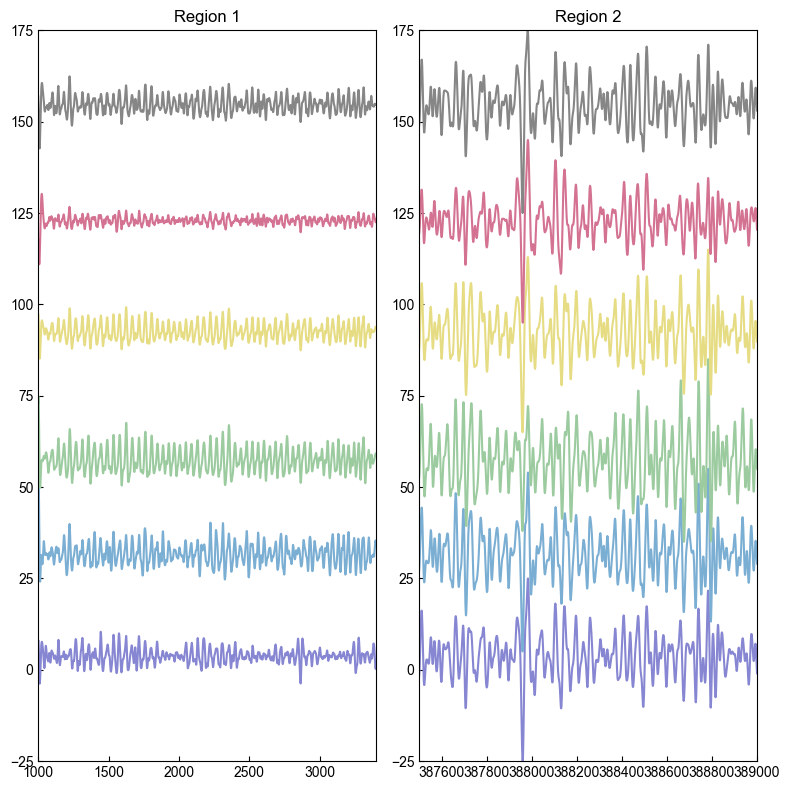

In [72]:
ppg_region_start_1 = 1000
ppg_region_end_1 = 3400

ppg_region_start_2 = 387500
ppg_region_end_2 = 389000

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()


sample_rate = 30.0
y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()

# 520S2

In [22]:
processor.load_data('../data/spectraderama_data_2025-03-25_sattac520S2.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (426807, 6)
First few rows:
      0     1     2      3      4     5
0  29.0  32.0  83.0  277.0  465.0  78.0
1  29.0  32.0  83.0  277.0  465.0  78.0
2  28.0  31.0  80.0  267.0  448.0  76.0
3  28.0  31.0  80.0  267.0  447.0  75.0
4  28.0  31.0  80.0  267.0  449.0  75.0


In [28]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=2.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (426807, 6)


In [35]:
t1 = 100
t2 = 423000
d = 300

time_limits_1 = (t1, t1 + d)
time_limits_2 = (t2, t2 + d)

amplitude_limits = (-25, 25)

# Use processor's normalize method with both time regions
processor.normalize(time_limits_1, time_limits_2, amplitude_limits=amplitude_limits)

# Get normalized data
timestamp, channels_swt_f_normalized = processor.get_data()
print(f"Normalized data shape: {channels_swt_f_normalized.shape}")

Normalized data shape: (426807, 6)


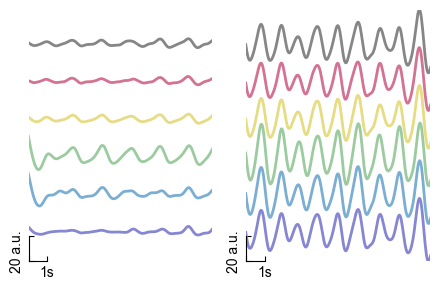

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(4.5, 3))

sample_rate = 30.0
y_offset = 30  # Small offset between channels

# Left subplot - first time region
ax_left = axes[0]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_left.plot(timestamp, y, color=colors[i], alpha=1, linewidth=2)

ax_left.set_xlim(*time_limits_1)
ax_left.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (30 samples)
ax_left.spines['bottom'].set_bounds(time_limits_1[0], time_limits_1[0] + 30)
# Left spine: show only 20 units
ax_left.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_left.spines['top'].set_visible(False)
ax_left.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_left.set_xticks([time_limits_1[0], time_limits_1[0] + 30])
ax_left.set_xticklabels(['', '1s'])
ax_left.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_left.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_left.tick_params(axis='both', which='both', direction='in')

# Right subplot - second time region
ax_right = axes[1]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_right.plot(timestamp, y, color=colors[i], alpha=1, linewidth=2)

ax_right.set_xlim(*time_limits_2)
ax_right.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (30 samples)
ax_right.spines['bottom'].set_bounds(time_limits_2[0], time_limits_2[0] + 30)
# Left spine: show only 20 units
ax_right.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_right.spines['top'].set_visible(False)
ax_right.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_right.set_xticks([time_limits_2[0], time_limits_2[0] + 30])
ax_right.set_xticklabels(['', '1s'])
ax_right.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_right.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_right.tick_params(axis='both', which='both', direction='in')

plt.tight_layout()
# plt.savefig('../figures/fig1/mode_a_sample.png', dpi=600, bbox_inches='tight')
plt.show()


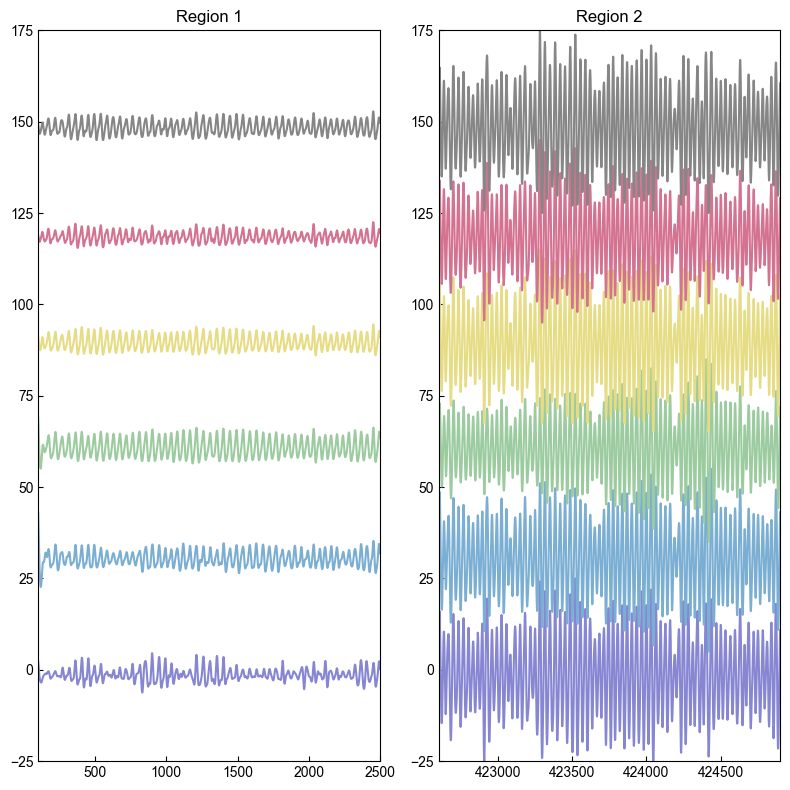

In [58]:
ppg_region_start_1 = 100
ppg_region_end_1 = 2500

ppg_region_start_2 = 422600
ppg_region_end_2 = 424900

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()


sample_rate = 30.0
y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()

# 555S1

In [73]:
processor.load_data('../data/spectraderama_data_2025-03-26_sattac555S1.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (343404, 6)
First few rows:
     0    1     2     3    4     5
0  2.0  5.0  13.0  14.0  8.0  14.0
1  2.0  5.0  13.0  14.0  8.0  14.0
2  2.0  5.0  13.0  14.0  8.0  14.0
3  2.0  4.0  12.0  14.0  8.0  13.0
4  2.0  4.0  12.0  14.0  8.0  13.0


In [87]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=2.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (343404, 6)


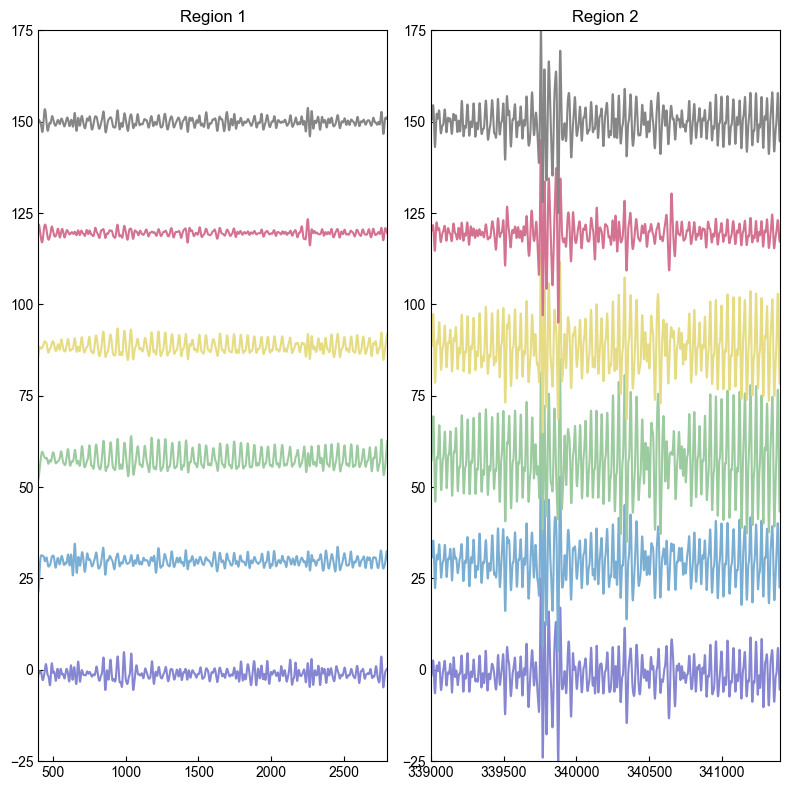

In [88]:
ppg_region_start_1 = 400
ppg_region_end_1 = 2800

ppg_region_start_2 = 339000
ppg_region_end_2 = 341400

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()


sample_rate = 30.0
y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()

# 563S2

In [89]:
processor.load_data('../data/spectraderama_data_2025-03-24_sattac563S2.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (31710, 6)
First few rows:
     0    1     2     3     4     5
0  2.0  6.0  18.0  18.0   9.0  13.0
1  2.0  6.0  18.0  18.0   9.0  13.0
2  2.0  6.0  18.0  18.0   9.0  13.0
3  2.0  6.0  17.0  19.0  10.0  13.0
4  3.0  6.0  17.0  19.0  10.0  13.0


(26600.0, 29000.0)

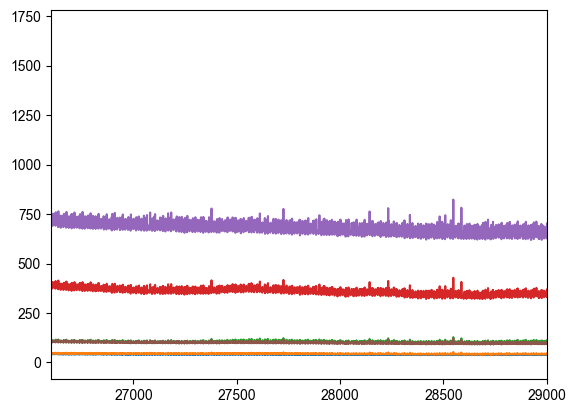

In [99]:
plt.plot(timestamp, channels)
# plt.xlim(1600, 4000)
plt.xlim(26600, 29000)

In [100]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=2.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (31710, 6)


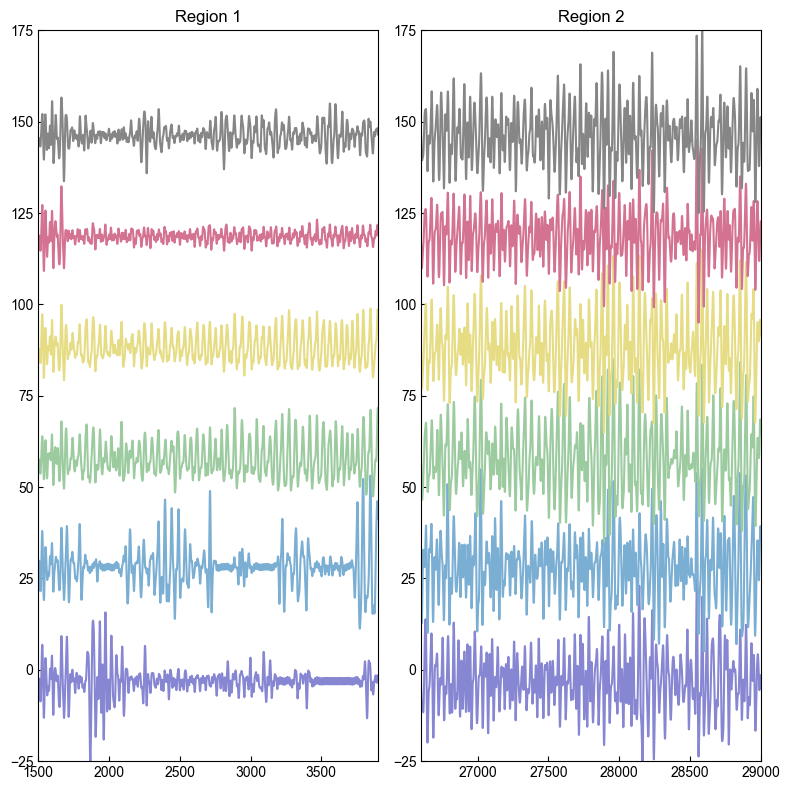

In [102]:
ppg_region_start_1 = 1500
ppg_region_end_1 = 3900

ppg_region_start_2 = 26600
ppg_region_end_2 = 29000

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()


sample_rate = 30.0
y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()